# 02 · Interpreting TabPFN's predictions

An in-context learner has no fitted coefficients or trees to inspect: its "model" of a dataset exists only during the forward pass that reads the context. The question here is whether the standard post-hoc explanations still work on it, and whether what they say is sensible. The test case is heart disease in the Statlog table, small and complete, where the clinical meaning of each measurement is well known, so an explanation that contradicts the medicine would be easy to spot.

Three explanations, from local to global:

- **SHAP waterfalls** break one patient's predicted risk into contributions from each measurement.
- **A SHAP beeswarm** shows those contributions across many patients and ranks the features.
- **Partial dependence curves** show how the average predicted risk moves as one measurement sweeps its range.

All three only query the model's predictions, so they treat TabPFN as a black box, exactly as they would treat any other classifier. The [results page](docs/results/02-interpreting-predictions.md) records the numbers this notebook produces.

## 1. Setup

In [1]:
import json
from pathlib import Path

import numpy as np
from sklearn.metrics import roc_auc_score

from tabpfn import TabPFNClassifier

from helper import (
    CONTINUOUS,
    categorical_indices,
    configure_plots,
    init_tabpfn,
    load_statlog_heart,
    make_shap_explainer,
    plot_beeswarm,
    plot_partial_dependence,
    plot_patient_waterfall,
    top_continuous_features,
)

RANDOM_STATE = 0

configure_plots(plots=True)
version = init_tabpfn()

TabPFN v3.5 weights, running locally


## 2. Data

The Statlog heart table: 270 patients, 13 measurements, no missing values, 120 with heart disease. A stratified split keeps 200 patients as context and 70 for testing. The measurements are under readable names, and seven of them are codes for categories (sex, chest-pain type, fasting blood sugar above 120 mg/dl, resting ECG result, exercise-induced angina, slope of the ST segment, thalassemia type); their positions are passed to TabPFN so it treats them as categories rather than numbers.

In [2]:
X_train, X_test, y_train, y_test = load_statlog_heart(
    train_size=200,
    test_size=70,
)

feature_names = list(X_train.columns)
cat_idx = categorical_indices(feature_names)

X_train.head(3)

,age,sex,chest_pain_type,resting_bp,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,n_major_vessels,thalassemia
12,44.0,1.0,3.0,140.0,235.0,0.0,2.0,180.0,0.0,0.0,1.0,0.0,3.0
66,51.0,1.0,4.0,140.0,261.0,0.0,2.0,186.0,1.0,0.0,1.0,0.0,3.0
68,44.0,0.0,3.0,118.0,242.0,0.0,0.0,149.0,0.0,0.3,2.0,1.0,3.0


In [3]:
y_train.head(3)

12    0
66    0
68    0
Name: heart_disease, dtype: int64

## 3. A model with a cached context

Every explanation below asks the model for thousands of predictions on slightly altered patients. Without a cache, each of those calls would preprocess and re-encode the 200 context patients again. With `fit_mode="fit_with_cache"`, `fit` preprocesses the context once and keeps the transformer's key and value tensors for it, so each later call only processes the new rows.

In [4]:
clf = TabPFNClassifier(
    fit_mode="fit_with_cache",
    categorical_features_indices=cat_idx,
    random_state=RANDOM_STATE,
)
clf.fit(X_train.values, y_train.values)

proba_test = clf.predict_proba(X_test.values)[:, 1]
test_auc = roc_auc_score(y_test, proba_test)
print(f"test AUC {test_auc:.3f}")

test AUC 0.916


## 4. SHAP values

For a patient $x$ and the model's predicted risk $f(x)$, SHAP assigns each feature $j$ a contribution $\phi_j(x)$ such that

$$
f(x) = \phi_0 + \sum_{j=1}^{13} \phi_j(x),
$$

where $\phi_0$, the base value, is the average predicted risk over a background set of patients. A feature's contribution is its average effect on the prediction when it is added to coalitions of the other features, with "absent" features filled in from the background patients. The permutation estimator used here samples orderings of the features and satisfies the sum exactly by construction. The background is 10 context patients drawn at random; it defines what "average patient" means, so a different background shifts $\phi_0$ and, to a lesser degree, the contributions.

Ten test patients are explained, which takes about a minute each on a laptop CPU.

In [5]:
explainer = make_shap_explainer(clf, X_train, n_background=10, seed=RANDOM_STATE)

In [6]:
N_EXPLAIN = 10

X_explain = X_test.iloc[:N_EXPLAIN]
shap_values = explainer(X_explain.values, silent=True)
shap_values.display_data = X_explain.values

predicted = clf.predict_proba(X_explain.values)[:, 1]
reconstructed = shap_values.values.sum(axis=1) + shap_values.base_values
additivity_error = float(np.abs(reconstructed - predicted).max())
print(f"explained {len(X_explain)} patients; "
      f"largest |base + sum of contributions - predicted risk| = {additivity_error:.1e}")

explained 10 patients; largest |base + sum of contributions - predicted risk| = 5.9e-08


### Single patients

Two cases: the patient with the highest predicted risk, and the one closest to the 50% threshold, where the decision is most fragile. Each waterfall starts at the base value $\phi_0$ at the bottom and adds one feature's contribution per bar, red for features that raise the risk and blue for those that lower it, until it reaches that patient's predicted risk at the top.

In [7]:
idx_high = int(np.argmax(predicted))
idx_borderline = int(np.argmin(np.abs(predicted - 0.5)))

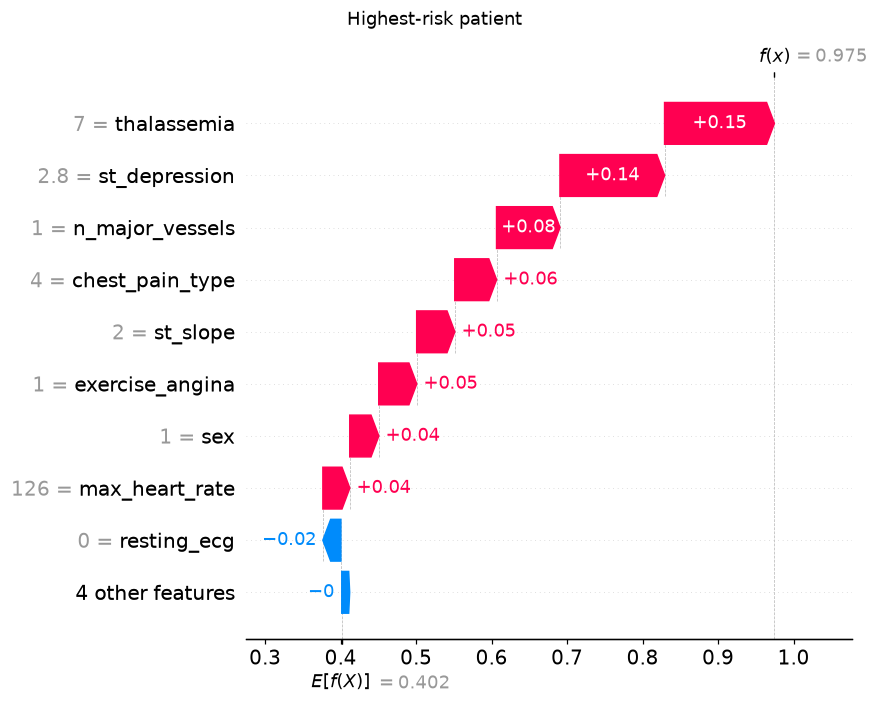

In [8]:
plot_patient_waterfall(shap_values, idx_high, "Highest-risk patient")

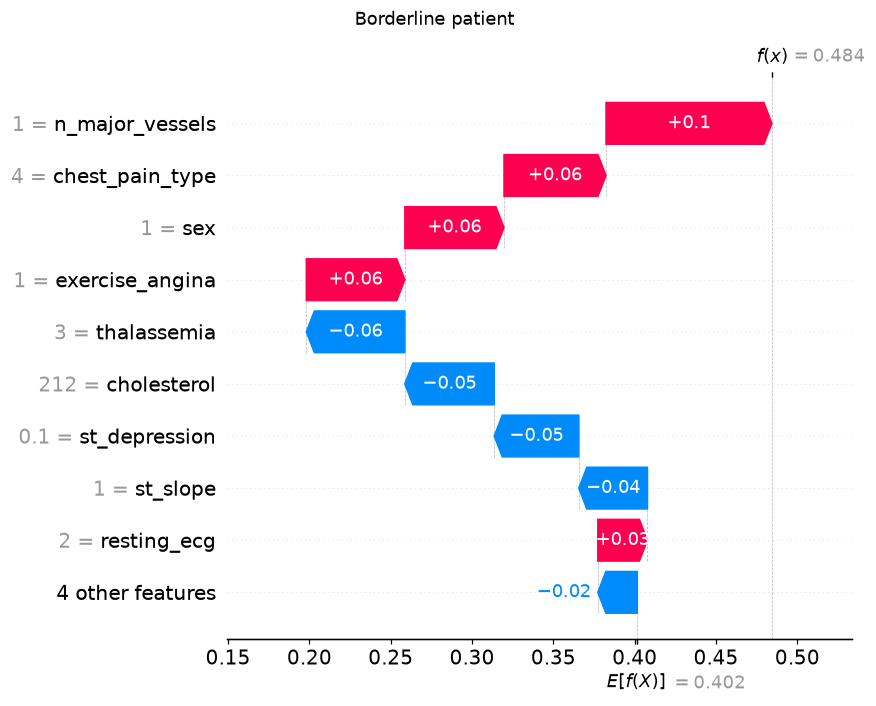

In [9]:
plot_patient_waterfall(shap_values, idx_borderline, "Borderline patient")

## 5. Which features matter

The beeswarm puts every explained patient's contribution for every feature on one plot. Features are ranked from the top by their mean absolute contribution. Each dot is one patient; its horizontal position is the contribution, and its colour is the feature's value for that patient, from low (blue) to high (red). A feature whose red dots sit on the right raises the predicted risk when it is high. With ten patients the ranking is indicative, not settled.

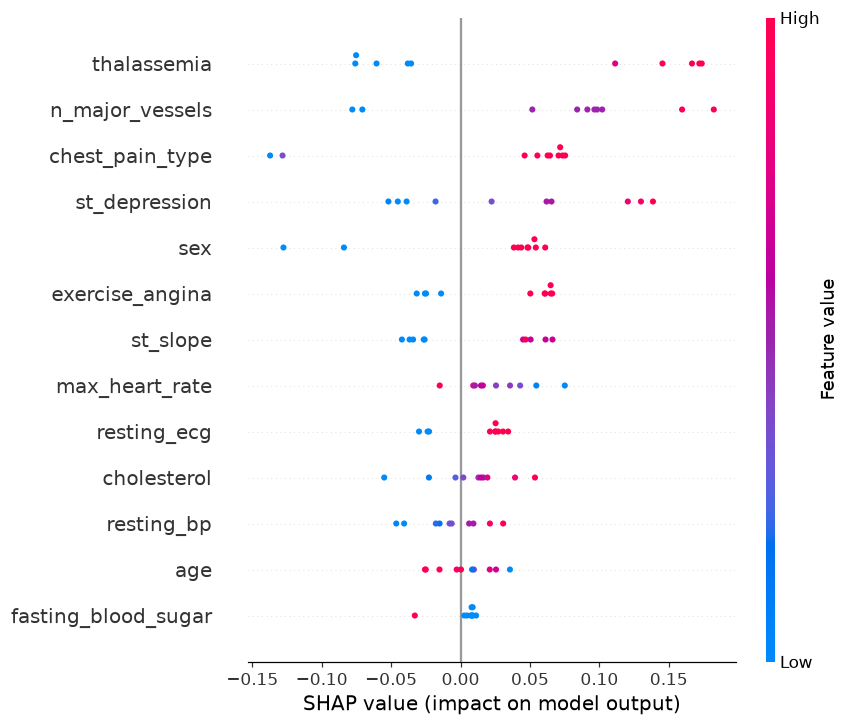

In [10]:
plot_beeswarm(shap_values, len(feature_names))

## 6. Partial dependence

SHAP explains particular predictions. Partial dependence describes the model's response to one feature on average: for a grid of values $v$ of feature $j$, set feature $j$ to $v$ for every context patient, keep their other measurements, and average the predicted risk,

$$
\mathrm{PD}_j(v) = \frac{1}{n} \sum_{i=1}^{n} f\left(x_i \text{ with } x_{ij} = v\right).
$$

The curves below are drawn for the four continuous measurements with the largest mean absolute SHAP contribution, on a shared vertical axis so their effect sizes can be compared directly. The grey ticks along the bottom are the context patients' actual values: where they are sparse, the curve rests on few real patients. Because partial dependence changes one feature while holding the others fixed, it can visit combinations that never occur together, such as a very high maximum heart rate in an eighty-year-old, and is least reliable for features that are strongly correlated with others.

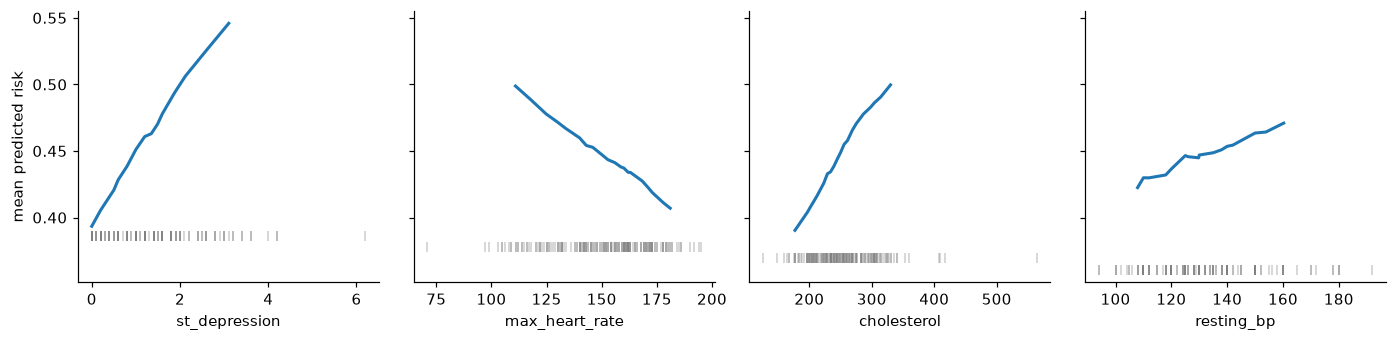

In [11]:
top_continuous = top_continuous_features(shap_values, feature_names, CONTINUOUS)

curves = plot_partial_dependence(clf, X_train.values, top_continuous, feature_names)

## 7. Reading the explanations

These are statements about the model, not about the patients' biology. A large contribution says the model leans on that measurement to separate the outcomes in this context; it does not say that changing the measurement would change the disease. Within that limit, the explanations can be checked against what is known clinically, which is what makes this table a good test case, and the check is part of what the results page records.

The last cell writes this run's numbers to the report the results page cites.

In [12]:
importance = np.abs(shap_values.values).mean(axis=0)
order = np.argsort(importance)[::-1]

report = {
    "notebook": "02_interpreting_predictions.ipynb",
    "tabpfn_version": version,
    "random_state": RANDOM_STATE,
    "data": {"n_context": len(X_train), "n_test": len(X_test),
             "test_positive_rate": float(y_test.mean())},
    "test_auc": float(test_auc),
    "shap": {
        "n_explained": N_EXPLAIN,
        "n_background": 10,
        "base_value": float(np.mean(shap_values.base_values)),
        "max_additivity_error": additivity_error,
        "mean_abs_contribution": {feature_names[i]: float(importance[i]) for i in order},
        "mean_contribution": {feature_names[i]: float(shap_values.values[:, i].mean()) for i in order},
        "highest_risk_patient": {"index": idx_high, "predicted": float(predicted[idx_high]),
                                 "actual": int(y_test.iloc[idx_high])},
        "borderline_patient": {"index": idx_borderline, "predicted": float(predicted[idx_borderline]),
                               "actual": int(y_test.iloc[idx_borderline])},
    },
    "partial_dependence": {
        name: {"grid": grid.round(3).tolist(), "mean_risk": risk.round(4).tolist()}
        for name, (grid, risk) in curves.items()
    },
}
path = Path("docs/results/reports/02-interpreting-predictions.json")
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(report, indent=1))
print(f"wrote {path}")

wrote docs/results/reports/02-interpreting-predictions.json
